**CLAP-general variant (phase6d_paradox_gallery_af_cg).** Copy of `phase6d_paradox_gallery_af.ipynb` with the CLAP audio representation replaced by `laion/larger_clap_general` (`audio_features_clap_general.parquet`; the HF `larger_clap_music` conversion is defective, see Phase 2d and 5p). Tracks robust under both the CLAP-general and the MuQ audio probes. Every output carries a `_cg` suffix; the original outputs are untouched.

# Phase 6d — Paradox Gallery with artist-grouped coherence folds

The original Figure 12 listed the 15 lowest Phase 4 coherence scores (CLAP audio probe, no uncertainty, probes scored
on their own training tracks). Phases 4b/4c showed that none of those 15 is a robust paradox once the audio probe is
MuQ. This gallery instead shows the tracks that are **robust paradoxes under both audio encoders**: the 95% bootstrap
interval of cross-fitted cosine coherence lies entirely below 0 with the CLAP probe (Phase 4b) *and* with the MuQ
probe (Phase 4c), lyrics probe SBERT in both. If Phase 4c section 9 has run, the status with the emotion-tuned
DistilRoBERTa lyrics probe is shown too.

Only `artist` and `title` are read from the metadata (for labelling); `moods`, `genres` and `themes` are not used.

**Outputs:** `outputs/paradox_gallery_v2.png`, `outputs/paradox_gallery_v2.csv`

**Artist-fold version (review response, 2026-10-11).** Built from Phase 6c with the coherence scores of Phase 4d (cross-fitting folds grouped by artist): every coherence input is an `_af` file and every output gets an `_af` suffix. Nothing else changes; the Phase 6c outputs are not modified.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
QLAB = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
QCOL = {'Q1': '#f4a261', 'Q2': '#e63946', 'Q3': '#457b9d', 'Q4': '#2a9d8f'}
C_AUDIO, C_TEXT, INK, MUTED = '#eb6834', '#1baf7a', '#2b2b2b', '#6f6f6f'

muq  = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq_af.parquet')).set_index('song_id')
clap = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_clap_af_cg.parquet')).set_index('song_id')
meta = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'), columns=['song_id', 'artist', 'title']).set_index('song_id')
ids  = pd.read_csv(os.path.join(OUT_DIR, 'coherence_paradox_both_encoders_af_cg.csv'))['song_id']
assert ((clap.loc[ids, 'status_cos'] == 'robust paradox') & (muq.loc[ids, 'status_cos'] == 'robust paradox')).all()

g = muq.loc[ids, ['quadrant', 'arousal', 'valence', 'pred_audio_arousal', 'pred_audio_valence',
                  'pred_lyrics_arousal', 'pred_lyrics_valence', 'coh_cos', 'coh_cos_lo', 'coh_cos_hi', 'err_audio', 'err_lyrics']]
g = g.join(clap[['coh_cos', 'coh_cos_lo', 'coh_cos_hi']].add_suffix('_clap')).join(meta)
g['wrong_probe'] = np.where(g.err_audio > g.err_lyrics, 'audio', 'lyrics')
emo_path = os.path.join(OUT_DIR, 'coherence_muq_emoroberta_af.parquet')
if os.path.exists(emo_path):
    g = g.join(pd.read_parquet(emo_path).set_index('song_id')['status_cos_emoroberta'])
g = g.sort_values('coh_cos').reset_index()
g.insert(0, 'rank', np.arange(1, len(g) + 1))
cols = ['rank', 'song_id', 'artist', 'title', 'quadrant', 'arousal', 'valence', 'pred_audio_arousal', 'pred_audio_valence',
        'pred_lyrics_arousal', 'pred_lyrics_valence', 'coh_cos', 'coh_cos_lo', 'coh_cos_hi', 'coh_cos_clap',
        'coh_cos_lo_clap', 'coh_cos_hi_clap', 'wrong_probe'] + (['status_cos_emoroberta'] if 'status_cos_emoroberta' in g else [])
g[cols].to_csv(os.path.join(OUT_DIR, 'paradox_gallery_v2_af_cg.csv'), index=False)
pd.set_option('display.width', 250)
print(g[['rank', 'artist', 'title', 'quadrant', 'coh_cos', 'coh_cos_clap', 'wrong_probe']
        + (['status_cos_emoroberta'] if 'status_cos_emoroberta' in g else [])].round(3).to_string(index=False))
print('\nquadrants:', g.quadrant.value_counts().sort_index().to_dict(), '| wrong probe:', g.wrong_probe.value_counts().to_dict())

 rank                  artist                            title quadrant  coh_cos  coh_cos_clap wrong_probe status_cos_emoroberta
    1             Robben Ford           You Cut Me to the Bone       Q3   -1.000        -0.999       audio        robust paradox
    2               New Order                     All Day Long       Q3   -1.000        -0.959       audio        robust paradox
    3                Lou Reed                     Modern Dance       Q3   -1.000        -0.997      lyrics             uncertain
    4               Bob Dylan             You're Gonna Quit Me       Q4   -1.000        -0.982      lyrics             uncertain
    5                  Clutch              The Elephant Riders       Q2   -0.998        -0.775      lyrics        robust paradox
    6             Chumbawamba               I Did It for Alfie       Q4   -0.998        -0.994      lyrics       robust coherent
    7          Paul McCartney                   Getting Closer       Q1   -0.997        -0.990   

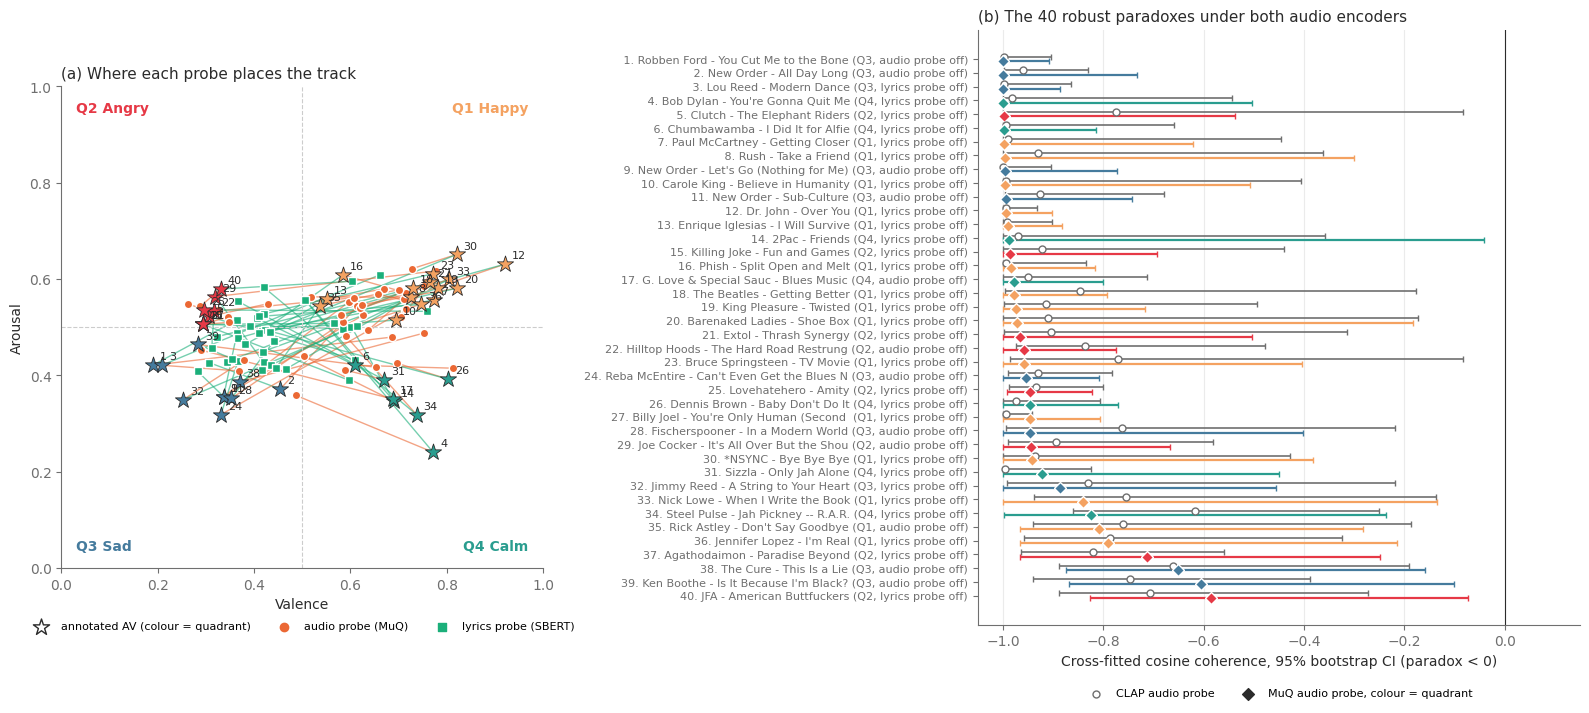

Saved: paradox_gallery_v2_af.png, paradox_gallery_v2_af.csv


In [2]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': INK, 'font.size': 10})
fig, (ax, bx) = plt.subplots(1, 2, figsize=(16, 7.2), gridspec_kw={'width_ratios': [1, 1.25]})

# (a) AV plane: annotated label, MuQ audio prediction, SBERT lyrics prediction
ax.axhline(0.5, color='#cccccc', lw=0.8, ls='--'); ax.axvline(0.5, color='#cccccc', lw=0.8, ls='--')
for q, (x, y) in {'Q1': (0.97, 0.97), 'Q2': (0.03, 0.97), 'Q3': (0.03, 0.03), 'Q4': (0.97, 0.03)}.items():
    ax.text(x, y, f'{q} {QLAB[q]}', ha='right' if x > 0.5 else 'left', va='top' if y > 0.5 else 'bottom',
            color=QCOL[q], fontsize=10, fontweight='bold')
for _, r in g.iterrows():
    for px, py, c in [(r.pred_audio_valence, r.pred_audio_arousal, C_AUDIO), (r.pred_lyrics_valence, r.pred_lyrics_arousal, C_TEXT)]:
        ax.plot([r.valence, px], [r.arousal, py], color=c, lw=1, alpha=0.6, zorder=1)
    ax.scatter(r.pred_audio_valence, r.pred_audio_arousal, marker='o', s=36, color=C_AUDIO, edgecolor='white', zorder=3)
    ax.scatter(r.pred_lyrics_valence, r.pred_lyrics_arousal, marker='s', s=36, color=C_TEXT, edgecolor='white', zorder=3)
    ax.scatter(r.valence, r.arousal, marker='*', s=150, color=QCOL[r.quadrant], edgecolor=INK, lw=0.6, zorder=4)
    ax.annotate(str(r['rank']), (r.valence, r.arousal), xytext=(5, 4), textcoords='offset points', fontsize=8, color=INK, zorder=5)
ax.scatter([], [], marker='*', s=150, color='white', edgecolor=INK, label='annotated AV (colour = quadrant)')
ax.scatter([], [], marker='o', s=36, color=C_AUDIO, label='audio probe (MuQ)')
ax.scatter([], [], marker='s', s=36, color=C_TEXT, label='lyrics probe (SBERT)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
ax.set_xlabel('Valence'); ax.set_ylabel('Arousal')
ax.set_title('(a) Where each probe places the track', loc='left', fontsize=11, color=INK)
ax.legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=3)

# (b) coherence with 95% bootstrap CI under both audio encoders
#     (near -1 the point estimate from the full-data probe can fall just outside the bootstrap percentile interval;
#      whiskers are clipped at 0 length there)
y = np.arange(len(g))[::-1]
for yi, (_, r) in zip(y, g.iterrows()):
    bx.errorbar(r.coh_cos_clap, yi + 0.17, xerr=[[max(0, r.coh_cos_clap - r.coh_cos_lo_clap)], [max(0, r.coh_cos_hi_clap - r.coh_cos_clap)]],
                fmt='o', ms=5, color=MUTED, mfc='white', capsize=2, lw=1.2)
    bx.errorbar(r.coh_cos, yi - 0.17, xerr=[[max(0, r.coh_cos - r.coh_cos_lo)], [max(0, r.coh_cos_hi - r.coh_cos)]],
                fmt='D', ms=6, color=QCOL[r.quadrant], capsize=2, lw=1.6, mec='white')
bx.axvline(0, color=INK, lw=0.8)
bx.set_yticks(y)
bx.set_yticklabels([f"{r['rank']:>2}. {r.artist[:22]} - {r.title[:26]} ({r.quadrant}, {r.wrong_probe} probe off)"
                    for _, r in g.iterrows()], fontsize=8)
bx.scatter([], [], marker='o', s=25, facecolor='white', edgecolor=MUTED, label='CLAP audio probe')
bx.scatter([], [], marker='D', s=36, color=INK, label='MuQ audio probe, colour = quadrant')
bx.set_xlim(-1.05, 0.15); bx.set_xlabel('Cross-fitted cosine coherence, 95% bootstrap CI (paradox < 0)')
bx.set_title(f'(b) The {len(g)} robust paradoxes under both audio encoders', loc='left', fontsize=11, color=INK)
bx.legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=2); bx.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'paradox_gallery_v2_af_cg.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: paradox_gallery_v2_af.png, paradox_gallery_v2_af.csv')